# Ames Housing — Regression: Predicting `Year Built`

**Research Question:** Given a house's physical characteristics and quality
attributes, can we predict its **construction year**?

| Step | Description |
|------|-------------|
| 1 | Load preprocessed splits from `preprocessed_data.pkl` |
| 2 | Define 9 regression models |
| 3 | Train & evaluate all models |
| 4 | 5-fold cross-validation |
| 5 | Actual vs Predicted visualisation |
| 6 | Hyperparameter tuning (GridSearch / RandomizedSearch) |
| 7 | Final evaluation of tuned models |

> **Prerequisite:** run `preprocessing.ipynb` first to generate `preprocessed_data.pkl`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from scipy.stats import uniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

In [2]:
with open('preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X            = data['X']
y            = data['y']
X_train      = data['X_train']
X_test       = data['X_test']
y_train      = data['y_train']
y_test       = data['y_test']
preprocessor = data['preprocessor']

print(f'X_train : {X_train.shape}  |  X_test : {X_test.shape}')
print(f'y range : {int(y.min())} to {int(y.max())}')

X_train : (2344, 71)  |  X_test : (586, 71)
y range : 1872 to 2010


## Model Selection

Nine regressors are included to cover a broad range of learning strategies: a linear baseline (Linear Regression), a regularised linear model (Ridge), a decision tree, random forest, gradient boosting, XGBoost, support vector regression, k-nearest neighbours, and a multi-layer perceptron. Note: Polynomial Regression was replaced with Ridge because applying degree-2 expansion to the 150+ preprocessed features produces an ill-conditioned ~11,000-feature matrix that makes ordinary least squares numerically unstable.

In [3]:
models = {
    'Linear Regression':      LinearRegression(),
    'Ridge Regression':       Ridge(alpha=1.0),
    'Decision Tree':          DecisionTreeRegressor(random_state=42),
    'Random Forest':          RandomForestRegressor(random_state=42),
    'Gradient Boosting':      GradientBoostingRegressor(random_state=42),
    'XGBoost':                XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
    'K-Nearest Neighbors':    KNeighborsRegressor(n_neighbors=5),
    'Neural Network':         MLPRegressor(random_state=42, max_iter=2000),
}

In [4]:
def evaluation_matrix(model_name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE':   round(mae,  4),
        'MSE':   round(mse,  4),
        'RMSE':  round(rmse, 4),
        'R2':    round(r2,   4),
    }

## Training & Evaluation

In [5]:
trained_models = {}
eval_matrix    = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', clone(model)),
    ])
    pipeline.fit(X_train, y_train)
    X_test_t = pipeline[:-1].transform(X_test)
    y_pred   = pipeline[-1].predict(X_test_t)
    trained_models[model_name] = y_pred
    eval_matrix.append(evaluation_matrix(model_name, y_test, y_pred))

print('Training complete.')

Training complete.


In [6]:
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7.1521,95.3380,9.7641,0.8913
1,Ridge Regression,7.0868,93.7295,9.6814,0.8931
2,Decision Tree,2.3737,42.3567,6.5082,0.9517
3,Random Forest,2.0178,23.5070,4.8484,0.9732
4,Gradient Boosting,3.6489,39.9885,6.3236,0.9544
5,XGBoost,2.6048,28.3933,5.3285,0.9676
6,Support Vector Regressor,6.8447,123.7657,11.1250,0.8589
7,K-Nearest Neighbors,4.9314,71.8395,8.4758,0.9181
8,Neural Network,6.6908,87.2436,9.3404,0.9005


In [7]:
best_mae_idx  = eval_matrix_df['MAE'].idxmin()
best_rmse_idx = eval_matrix_df['RMSE'].idxmin()
best_r2_idx   = eval_matrix_df['R2'].idxmax()

best_row = {
    'Model': 'Best Model',
    'MAE':   eval_matrix_df.loc[best_mae_idx,  'Model'],
    'MSE':   eval_matrix_df.loc[best_mae_idx,  'Model'],
    'RMSE':  eval_matrix_df.loc[best_rmse_idx, 'Model'],
    'R2':    eval_matrix_df.loc[best_r2_idx,   'Model'],
}
pd.concat([eval_matrix_df, pd.DataFrame([best_row])], ignore_index=True)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,7.1521,95.338,9.7641,0.8913
1,Ridge Regression,7.0868,93.7295,9.6814,0.8931
2,Decision Tree,2.3737,42.3567,6.5082,0.9517
3,Random Forest,2.0178,23.507,4.8484,0.9732
4,Gradient Boosting,3.6489,39.9885,6.3236,0.9544
5,XGBoost,2.6048,28.3933,5.3285,0.9676
6,Support Vector Regressor,6.8447,123.7657,11.125,0.8589
7,K-Nearest Neighbors,4.9314,71.8395,8.4758,0.9181
8,Neural Network,6.6908,87.2436,9.3404,0.9005
9,Best Model,Random Forest,Random Forest,Random Forest,Random Forest


## Cross-Validation (5-Fold)

In [8]:
cv_results = []
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    scores      = cross_val_score(pipe, X, y, cv=5, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-scores)
    cv_results.append({
        'Model':         name,
        'CV RMSE mean':  f'{rmse_scores.mean():.4f}',
        'CV RMSE std':   f'+/- {rmse_scores.std():.4f}',
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,Model,CV RMSE mean,CV RMSE std
0,Linear Regression,12.5437,+/- 5.3257
1,Ridge Regression,12.5154,+/- 5.3378
2,Decision Tree,7.6851,+/- 0.7638
3,Random Forest,5.2381,+/- 0.4485
4,Gradient Boosting,6.1017,+/- 0.5189
5,XGBoost,5.5886,+/- 0.7490
6,Support Vector Regressor,12.3818,+/- 1.5672
7,K-Nearest Neighbors,8.7599,+/- 1.1936
8,Neural Network,16.6615,+/- 11.5587


## Actual vs Predicted Construction Year

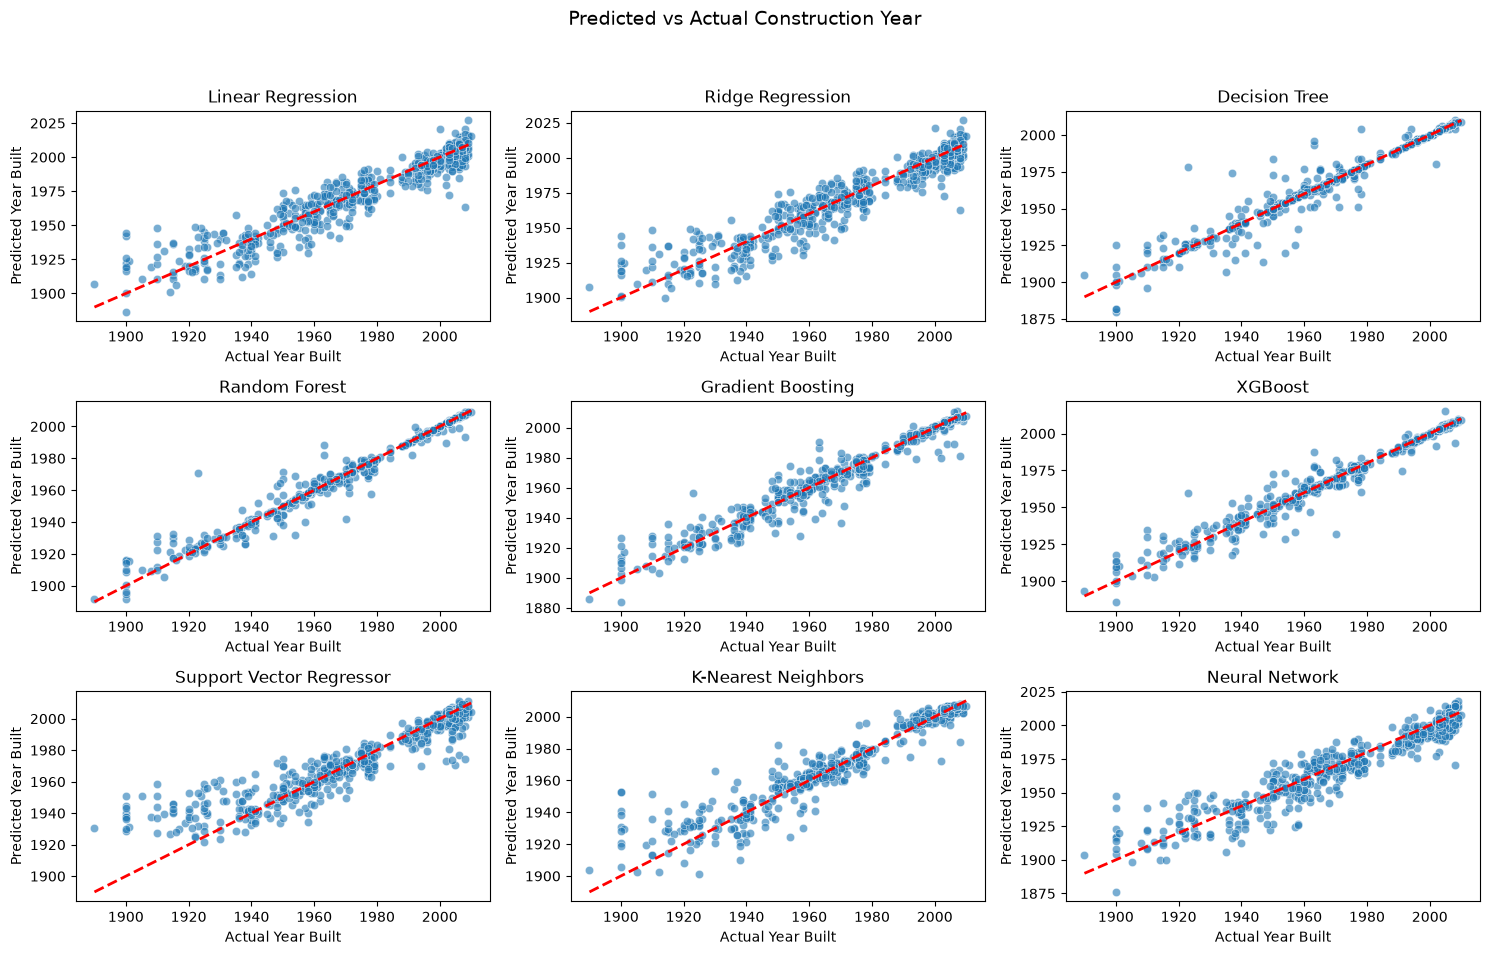

In [9]:
plt.figure(figsize=(15, 10))
plt.suptitle('Predicted vs Actual Construction Year', fontsize=14)

for i, (name, y_pred) in enumerate(trained_models.items(), 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Actual Year Built')
    plt.ylabel('Predicted Year Built')
    plt.title(name)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Hyperparameter Tuning

Top 4 performers tuned with cross-validated search:
- **Random Forest** & **XGBoost** → `RandomizedSearchCV` (large grid)
- **Gradient Boosting** & **SVR** → `GridSearchCV`

In [12]:
param_grids = {
    'Random Forest': {
        'model__n_estimators':      [50, 100, 200],
        'model__max_depth':         [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf':  [1, 2, 4],
    },
    'Gradient Boosting': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__max_depth':     [3, 5, 7],
    },
    'XGBoost': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': uniform(0.01, 0.3),
        'model__max_depth':     [3, 5, 7],
    },
    'Support Vector Regressor': {
        'model__kernel': ['linear', 'rbf'],
        'model__C':      [0.1, 1, 10],
        'model__gamma':  ['scale', 'auto'],
    },
}

In [13]:
tune_models = {
    'Random Forest':            RandomForestRegressor(random_state=42),
    'Gradient Boosting':        GradientBoostingRegressor(random_state=42),
    'XGBoost':                  XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
}
best_models = {}

In [14]:
for name, model in tune_models.items():
    print(f'Tuning {name}...')
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])

    if name in ['Random Forest', 'XGBoost']:
        search = RandomizedSearchCV(
            pipe, param_distributions=param_grids[name],
            n_iter=10, cv=5, scoring='neg_mean_squared_error',
            n_jobs=-1, random_state=42,
        )
    else:
        search = GridSearchCV(
            pipe, param_grid=param_grids[name],
            cv=5, scoring='neg_mean_squared_error', n_jobs=-1,
        )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f'  Best params : {search.best_params_}')
    print(f'  Best CV RMSE: {np.sqrt(-search.best_score_):.4f}')
    print()

Tuning Random Forest...
  Best params : {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 30}
  Best CV RMSE: 5.2513

Tuning Gradient Boosting...
  Best params : {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}
  Best CV RMSE: 5.4517

Tuning XGBoost...
  Best params : {'model__learning_rate': np.float64(0.19355586841671385), 'model__max_depth': 5, 'model__n_estimators': 200}
  Best CV RMSE: 5.4878

Tuning Support Vector Regressor...
  Best params : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
  Best CV RMSE: 9.5741



## Final Evaluation — Tuned Models

In [15]:
eval_matrix = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    eval_matrix.append(evaluation_matrix(name, y_test, y_pred))

eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,MAE,MSE,RMSE,R2
0,Random Forest,2.0239,23.7157,4.8699,0.9730
1,Gradient Boosting,2.4943,26.6520,5.1626,0.9696
2,XGBoost,2.6487,26.4812,5.1460,0.9698
3,Support Vector Regressor,4.9842,72.4686,8.5128,0.9174
